# Coupled-Mode Theory — Numerical Lab
**Yariv & Yeh, *Photonics*, Chapter 13, Sections 13.1–13.4**

## Learning objectives

- Understand the physical origin of coupling between optical waveguide modes.
- Derive and solve the coupled-mode equations.
- Explore how coupling strength and phase mismatch change power transfer.
- Check conservation of optical power.
- Compare analytical and numerical solutions.
- Design a directional coupler.

**Conventions:** The propagation coordinate $z$ and lengths are measured in $\mu\mathrm{m}$; propagation constants $\beta_j$, coupling coefficients $K_{ij}$, $\kappa$ which is constant (the length between the wave guide do not effect), and phase-mismatch parameter $\delta$ are measured in $\mu\mathrm{m}^{-1}$. We use the carrier convention $e^{i(\omega t-\beta z)}$.

## Theory 2 — Two waveguides and the slowly varying envelope approximation

For two nearby waveguides separated by a gap $d$, the evanescent tails of their fields may overlap. We approximate the full field by a superposition of the **uncoupled** modes:

$$
\mathbf E(x,y,z,t)\propto
A(z)\mathbf e_a(x,y)e^{i(\omega t-\beta_a z)}
+B(z)\mathbf e_b(x,y)e^{i(\omega t-\beta_b z)}.
$$

The complex envelopes $A(z)$ and $B(z)$ now vary with propagation distance. The field must satisfy Maxwell's equations and electromagnetic boundary conditions. For a source-free, nonmagnetic dielectric at fixed frequency, the frequency-domain electric-field equation is

$$
\nabla\times\nabla\times\mathbf E-\frac{\omega^2}{c^2}\epsilon_r(x,y)\mathbf E=0.
$$

After substituting the expansion, projecting onto the original modes, and applying the **slowly varying envelope approximation** (SVEA), the second derivatives of the amplitudes are neglected compared with terms proportional to $\beta_j$ times their first derivatives:

$$
\left|\frac{d^2 A}{dz^2}\right|\ll\left|\beta_a\frac{dA}{dz}\right|,\qquad
\left|\frac{d^2 B}{dz^2}\right|\ll\left|\beta_b\frac{dB}{dz}\right|.
$$

The coupled-mode model is an approximation: it assumes a suitable mode basis, weak enough perturbations/coupling, and a consistent mode normalization.

## Theory 3 — Coupled-mode equations and the four $K_{ij}$ coefficients

With the convention used in our notes, the equations are

$$
\boxed{\frac{dA}{dz}=-iK_{aa}A-iK_{ab}B e^{i(\beta_a-\beta_b)z}}
$$

$$
\boxed{\frac{dB}{dz}=-iK_{bb}B-iK_{ba}A e^{-i(\beta_a-\beta_b)z}}.
$$

The coefficients summarize the effect of the dielectric perturbation and modal overlap:

| Coefficient | Physical meaning |
|---|---|
| $K_{aa}$ | **Self-coupling**: correction to the phase propagation of mode $a$. |
| $K_{bb}$ | **Self-coupling**: correction to the phase propagation of mode $b$. |
| $K_{ab}$ | **Cross-coupling**: contribution of mode $b$ to the evolution of mode $a$. |
| $K_{ba}$ | **Cross-coupling**: contribution of mode $a$ to the evolution of mode $b$. |

For a lossless system with a power-normalized modal basis and Hermitian coupling description, $K_{aa},K_{bb}$ are real and $K_{ba}=K_{ab}^{*}$. This condition is required for the two-mode model to conserve total normalized power.

## Theory 4 — Effective propagation constants and phase mismatch

The self-coupling terms affect the phase of the two modes. Define

$$
\tilde\beta_a=\beta_a+K_{aa},\qquad
\tilde\beta_b=\beta_b+K_{bb}.
$$

The **full effective propagation-constant mismatch** is

$$
\boxed{\Delta\beta_{\mathrm{eff}}=\tilde\beta_a-\tilde\beta_b
=(\beta_a+K_{aa})-(\beta_b+K_{bb})}.
$$

For our $2\times 2$ Hamiltonian convention, we define **half** the mismatch as

$$
\boxed{\delta=\frac{\Delta\beta_{\mathrm{eff}}}{2}}.
$$

- $\delta=0$: effective phase matching; complete transfer is possible for constant, nonzero coupling in this idealized lossless model.
- $\delta\neq0$: the relative modal phase evolves, limiting the largest transferable power for constant coupling.

**Important distinction:** $\tilde\beta_{a,b}$ are the diagonal propagation constants after self-coupling corrections; they are not generally the propagation constants of the **coupled supermodes**.

## Theory 5 — Remove the self-coupling phase shifts

Introduce

$$
\tilde A(z)=A(z)e^{iK_{aa}z},\qquad
\tilde B(z)=B(z)e^{iK_{bb}z}.
$$

Assuming the coefficients are constant, differentiation gives

$$
\frac{d\tilde A}{dz}=e^{iK_{aa}z}\left(\frac{dA}{dz}+iK_{aa}A\right),
$$

and correspondingly for $\tilde B$. Substituting the original coupled equations cancels the diagonal self-coupling terms:

$$
\boxed{\frac{d\tilde A}{dz}=-iK_{ab}\tilde B e^{i2\delta z}},
\qquad
\boxed{\frac{d\tilde B}{dz}=-iK_{ba}\tilde A e^{-i2\delta z}}.
$$

The self-coupling terms still matter: they appear inside $\delta$. The tildes must be used on **both** modal amplitudes in these equations.

## Theory 6 — Rotating frame and effective Hamiltonian

Make one more phase transformation:

$$
\tilde A(z)=a(z)e^{i\delta z},\qquad
\tilde B(z)=b(z)e^{-i\delta z}.
$$

For constant $\delta$:

$$
\frac{d\tilde A}{dz}=e^{i\delta z}\left(\frac{da}{dz}+i\delta a\right),
\qquad
\frac{d\tilde B}{dz}=e^{-i\delta z}\left(\frac{db}{dz}-i\delta b\right).
$$

Substitution yields

$$
\frac{da}{dz}=-i\delta a-iK_{ab}b,\qquad
\frac{db}{dz}=i\delta b-iK_{ba}a.
$$

Writing $K_{ab}=\kappa$ and $K_{ba}=\kappa^*$ gives

$$
\boxed{
i\frac{d}{dz}\begin{pmatrix}a\\b\end{pmatrix}
=\underbrace{\begin{pmatrix}\delta&\kappa\\\kappa^*&-\delta\end{pmatrix}}_{H_{\mathrm{eff}}}
\begin{pmatrix}a\\b\end{pmatrix}}.
$$

The matrix is Hermitian when $\delta$ is real. It is mathematically analogous to a two-level Hamiltonian, with propagation distance $z$ in place of time. **Do not add an extra $-i$ on the right of the $i\,d/dz$ equation.** For numerical integration, the equivalent derivative equation is $d\mathbf a/dz=-iH_{\mathrm{eff}}\mathbf a$.

## Theory 7 — Conserved power and analytical prediction

For $\mathbf a(z)=(a,b)^T$ and a Hermitian $H_{\mathrm{eff}}$,

$$
\frac{d}{dz}(\mathbf a^\dagger\mathbf a)=0.
$$

Thus for a normalized input $a(0)=1$, $b(0)=0$,

$$
\boxed{P_a(z)+P_b(z)=|a(z)|^2+|b(z)|^2=1}.
$$

When $\delta$ and $\kappa$ are constant, define $S=\sqrt{|\kappa|^2+\delta^2}$. The transferred power is

$$
\boxed{P_b(z)=\frac{|\kappa|^2}{S^2}\sin^2(Sz)}\qquad(S>0),
$$

with $P_a(z)=1-P_b(z)$. If $S=0$, $P_b(z)=0$. In particular, for perfect phase matching ($\delta=0$) and real nonzero $\kappa$,

$$P_b(z)=\sin^2(\kappa z),\qquad L_{\mathrm{transfer}}=\frac{\pi}{2|\kappa|}.$$

**Prediction before running:** identical, phase-matched waveguides should periodically exchange power rather than show monotonic decay. Increasing $|\delta|$ lowers the maximum cross-port power. Increasing $|\kappa|$ shortens the transfer length when $\delta=0$.

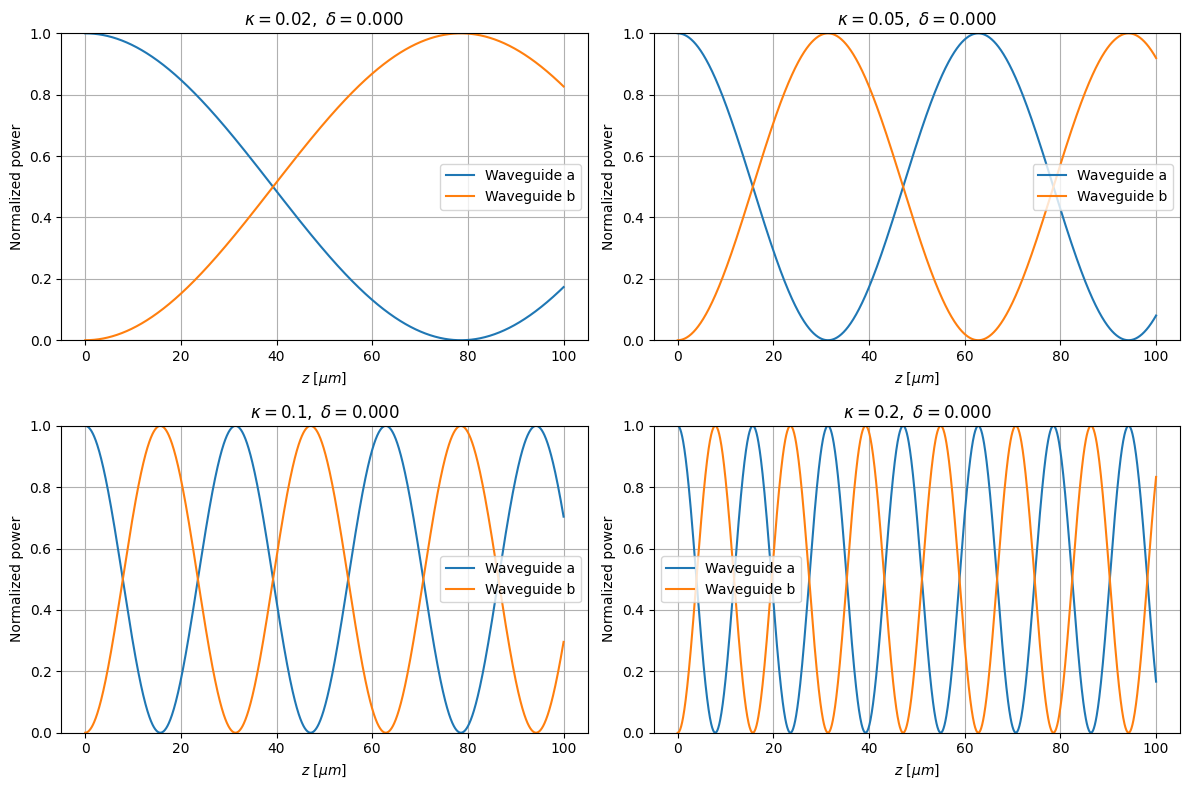

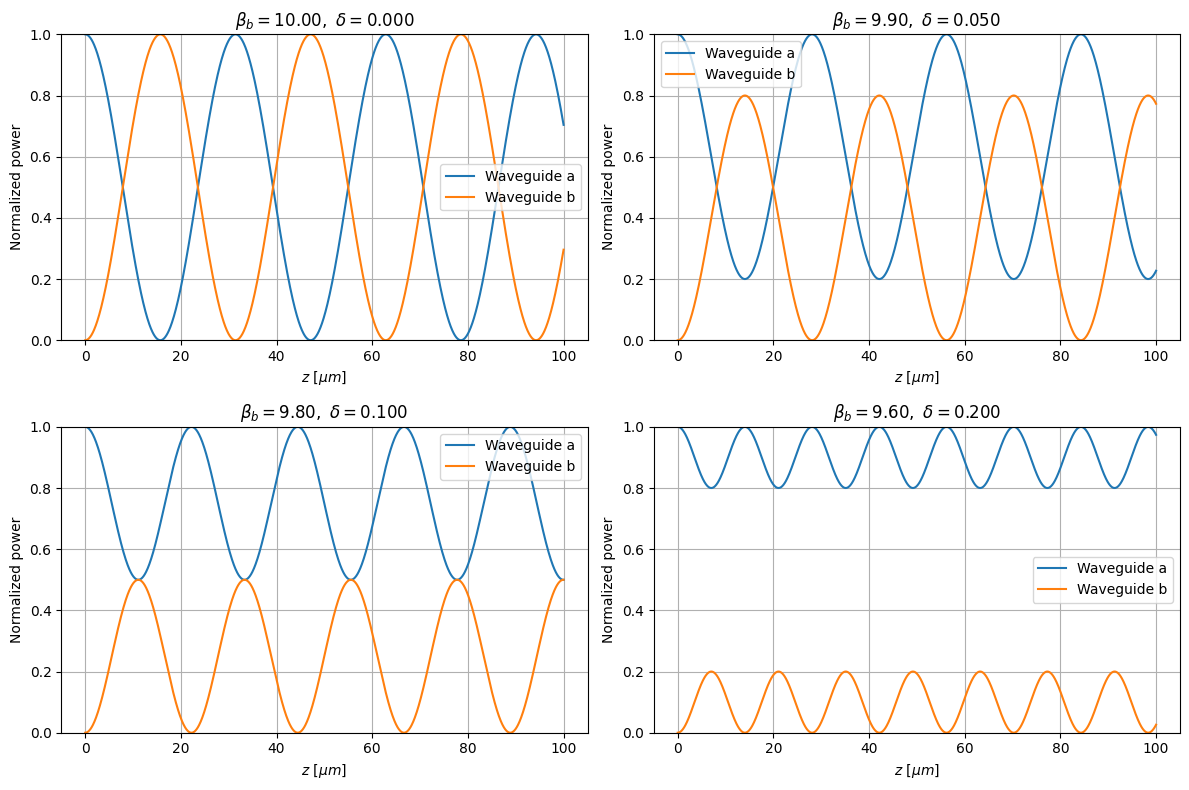

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from coupled_mode import delta, propagate, analytic_powers

z = np.linspace(0, 100, 1500)

# Initial condition: all power in waveguide a
initial = (1.0, 0.0)

# Propagation constants [1/um]
beta_a = 10.0
beta_b = 10.0

# Self-coupling coefficients [1/um]
Kaa = 0.0
Kbb = 0.0

# --------------------------- #
# Part 1: Scan kappa
# --------------------------- #

delta0 = delta(beta_a, beta_b, Kaa, Kbb)

kappa_values = [0.02, 0.05, 0.1, 0.2]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, kappa in zip(axes.flat, kappa_values):

    amplitudes = propagate(z, delta=delta0, kappa=kappa, initial=initial)

    Pa = np.abs(amplitudes[0])**2
    Pb = np.abs(amplitudes[1])**2

    ax.plot(z, Pa, label="Waveguide a")
    ax.plot(z, Pb, label="Waveguide b")

    ax.set_title(rf"$\kappa={kappa},\ \delta={delta0:.3f}$")
    ax.set_xlabel(r"$z\ [\mu m]$")
    ax.set_ylabel("Normalized power")
    ax.set_ylim(0, 1)
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()


# --------------------------- #
# Part 2: Scan delta via beta_b
# --------------------------- #

kappa0 = 0.1

beta_b_values = [10.0, 9.9, 9.8, 9.6]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, beta_b in zip(axes.flat, beta_b_values):

    delta0 = delta(beta_a, beta_b, Kaa, Kbb)

    amplitudes = propagate(z, delta=delta0, kappa=kappa0, initial=initial)

    Pa = np.abs(amplitudes[0])**2
    Pb = np.abs(amplitudes[1])**2

    ax.plot(z, Pa, label="Waveguide a")
    ax.plot(z, Pb, label="Waveguide b")

    ax.set_title(
        rf"$\beta_b={beta_b:.2f},\ \delta={delta0:.3f}$"
    )
    ax.set_xlabel(r"$z\ [\mu m]$")
    ax.set_ylabel("Normalized power")
    ax.set_ylim(0, 1)
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

## Geometry-dependent coupling

### 1. Physical interpretation: changing width versus changing separation

**Model and scope.** We now consider *two parallel, symmetric, 1D slab waveguides*, with a common core refractive index $n_c$, cladding index $n_s$, vacuum wavelength $\lambda_0$, core widths $w_a,w_b$, and an **edge-to-edge gap** $g$. Their **center-to-center separation** is

$$d=g+\frac{w_a+w_b}{2}. $$

For identical guides of width $w$, $d=g+w$. In the numerical experiments below, changing the gap means changing $d$ while **holding both widths fixed**. Changing width at fixed gap is a *different experiment*: the center spacing also changes geometrically.

The evanescent tail of a guided mode in the cladding decays approximately as $e^{-q_j |x|}$, with

$$k_0=\frac{2\pi}{\lambda_0},\qquad \beta_j=k_0 n_{\mathrm{eff},j},\qquad q_j=\sqrt{\beta_j^2-(k_0n_s)^2}.$$

Consequently the cross-coupling weakens approximately exponentially as the gap increases (for fixed widths):

$$\boxed{\kappa(g)\propto e^{-q g}}$$

for **identical** slab modes; for unequal guides the detailed overlap and both decay constants matter. The proportionality is not a universal expression for the prefactor.

**Changing the width** affects the isolated modal profile and $\beta_j$, which in turn affect $q_j$ and the cross-coupling overlap. If only one width changes, it generally also produces phase mismatch:

$$\boxed{\delta=\frac{\beta_a-\beta_b+K_{aa}-K_{bb}}{2}.}$$

Even if $\kappa$ increases, larger $|\delta|$ can reduce transfer. Therefore **do not conclude efficiency from $\kappa$ alone**.

For the initial condition $a(0)=1,b(0)=0$, constant real $\kappa$ and lossless propagation,

$$P_b(z)=\frac{\kappa^2}{\kappa^2+\delta^2}\sin^2\!\left(\sqrt{\kappa^2+\delta^2}\,z\right),\qquad P_a(z)=1-P_b(z).$$

$$\boxed{P_{b,\max}=\frac{\kappa^2}{\kappa^2+\delta^2}},\qquad
z_{\mathrm{first\ max}}=\frac{\pi}{2\sqrt{\kappa^2+\delta^2}}.$$

Only at phase matching ($\delta=0$) is the first complete-transfer length $L_c=\pi/(2|\kappa|)$. An off-resonant first maximum need **not** be complete transfer.

**Connection to reading:** Yariv & Yeh, Ch. 3 (TE slab modes) and Ch. 13 (directional coupling). The numerical model below is a *weak-coupling scalar TE overlap approximation* for symmetric planar slab guides; it is **not** a full-vector mode solver for realistic silicon strip waveguides or an exact formula for arbitrarily dissimilar modes.

### 2. Experiment A — change the width of one guide, fixed gap

Keep $w_b$ and the **edge-to-edge gap** constant, and vary $w_a$. This changes both $\kappa$ **and** $\delta$ because $\beta_a$ and the mode shape change. We plot the maximum possible transfer as well as transfer at a fixed device length $L$.

### 3. Experiment B — change only separation, both widths fixed

Now **hold $w_a=w_b$ fixed** and vary the edge-to-edge gap $g$. Since the guides are identical, symmetry gives $\delta=0$ (including the self-shifts). The coupling $\kappa$ decreases with $g$, and $L_c=\pi/(2\kappa)$ increases. However, $P_b(L)$ at a **fixed** $L$ oscillates with $\kappa(g)L$; it is not generally monotonic.

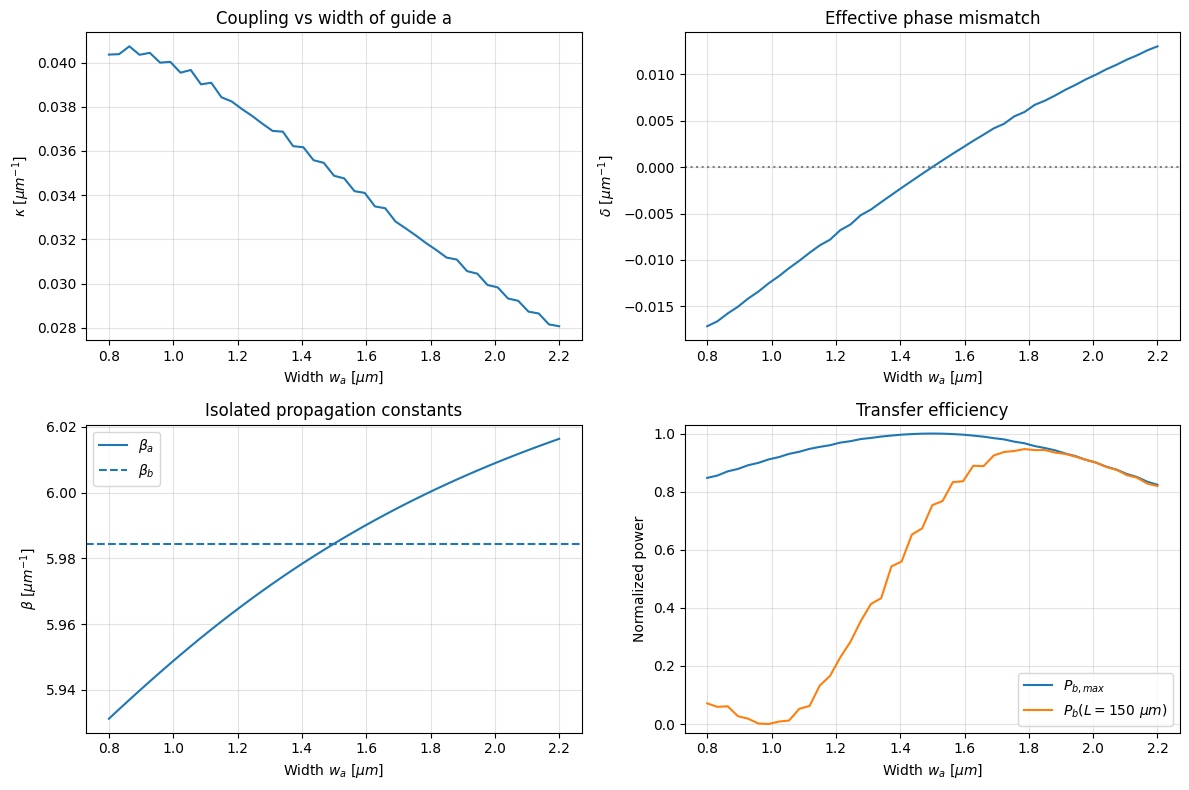

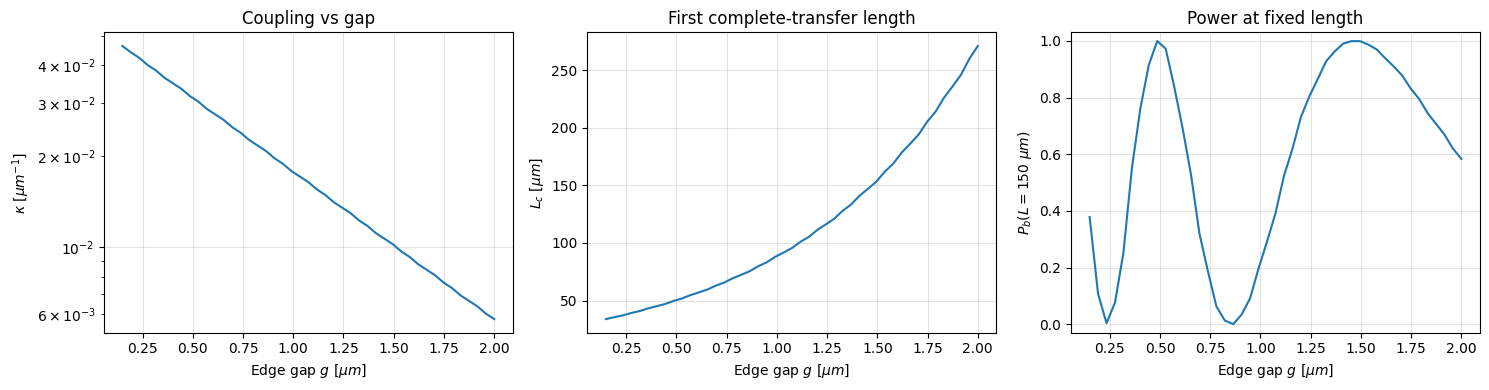

Maximum |delta| for identical guides: 0.0


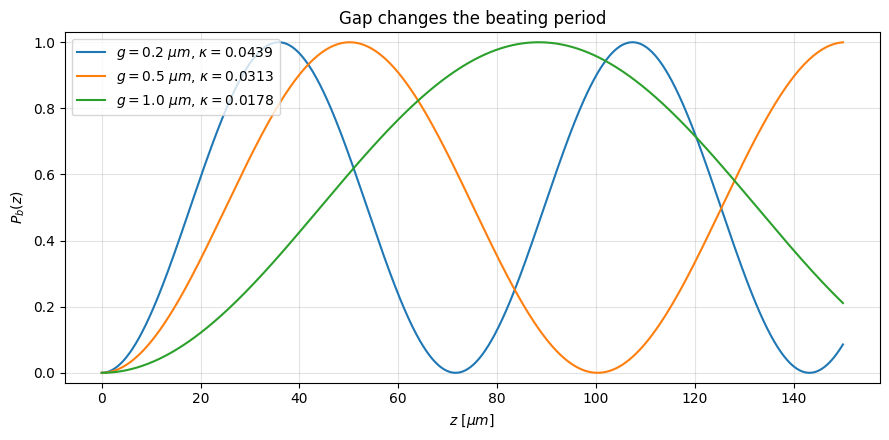

{'beta_a': np.float64(5.984460985751121), 'beta_b': np.float64(5.984460985751121), 'q_a': np.float64(1.1247323309289223), 'q_b': np.float64(1.1247323309289223), 'Kaa': np.float64(0.010253550534854033), 'Kbb': np.float64(0.010253550534854033), 'kappa': np.float64(0.03487974425614977), 'delta': np.float64(0.0), 'd': 1.9}


In [19]:
from coupled_mode import slab_cmt_geometry, run_geometry_sweeps
run_geometry_sweeps()

geom = slab_cmt_geometry(width_a=1.5, width_b=1.5, gap=0.4)
print(geom)
# Pass geom['delta'] and geom['kappa'] to your existing propagate function.